In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)
import seaborn as sns

DATA_PATH = 'C:\\Users\\amanm\\OneDrive\\Desktop\\dont open\\Career\\Breakthrough Team\\Personal\\data\\fraud_oracle.csv'   # change to your local path
TARGET = 'FraudFound_P'

## True EDA
* Dataset Overview — Number of rows, columns, feature types, and target variable.
* Target Distribution — Fraud vs. non-fraud counts and percentages; identify class imbalance.


In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape) # 15420 rows, 33 columns (features)
print(df.dtypes.value_counts()) # 24 str value features, 9 int value features
print(df[TARGET].value_counts()) # 14497 non-fraud, 923 fraud cases
print(df[TARGET].value_counts(normalize=True)) # 0.0598 fraud cases

(15420, 33)
str      24
int64     9
Name: count, dtype: int64
FraudFound_P
0    14497
1      923
Name: count, dtype: int64
FraudFound_P
0    0.940143
1    0.059857
Name: proportion, dtype: float64


* Missing Values — Identify missing columns, percentages, and patterns.
* Duplicate Records — Identify duplicate rows, claims, and potentially duplicated entities.

In [3]:
print("missing values: " + str(df.isnull().sum().sum())) # 0 missing values over all features

# duplicate check
# Find exact duplicate rows across all columns
exact_dups = df[df.duplicated()]
print("Exact Duplicate Rows:")
print(exact_dups)

missing values: 0
Exact Duplicate Rows:
Empty DataFrame
Columns: [Month, WeekOfMonth, DayOfWeek, Make, AccidentArea, DayOfWeekClaimed, MonthClaimed, WeekOfMonthClaimed, Sex, MaritalStatus, Age, Fault, PolicyType, VehicleCategory, VehiclePrice, FraudFound_P, PolicyNumber, RepNumber, Deductible, DriverRating, Days_Policy_Accident, Days_Policy_Claim, PastNumberOfClaims, AgeOfVehicle, AgeOfPolicyHolder, PoliceReportFiled, WitnessPresent, AgentType, NumberOfSuppliments, AddressChange_Claim, NumberOfCars, Year, BasePolicy]
Index: []

[0 rows x 33 columns]


* Feature Distributions — Examine numerical distributions, categorical frequencies, and skewness.
* Outlier Analysis — Identify unusual claim amounts, incident dates, ages, and other values.

                      count         mean          std     min      25%  \
WeekOfMonth         15420.0     2.788586     1.287585     1.0     2.00   
WeekOfMonthClaimed  15420.0     2.693969     1.259115     1.0     2.00   
Age                 15420.0    39.855707    13.492377     0.0    31.00   
PolicyNumber        15420.0  7710.500000  4451.514911     1.0  3855.75   
RepNumber           15420.0     8.483268     4.599948     1.0     5.00   
Deductible          15420.0   407.704280    43.950998   300.0   400.00   
DriverRating        15420.0     2.487808     1.119453     1.0     1.00   
Year                15420.0  1994.866472     0.803313  1994.0  1994.00   

                       50%       75%      max  
WeekOfMonth            3.0      4.00      5.0  
WeekOfMonthClaimed     3.0      4.00      5.0  
Age                   38.0     48.00     80.0  
PolicyNumber        7710.5  11565.25  15420.0  
RepNumber              8.0     12.00     16.0  
Deductible           400.0    400.00    700.0

C:\Users\amanm\AppData\Local\Temp\ipykernel_16320\4048110194.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include= ['object', 'category', 'bool']).columns.tolist()


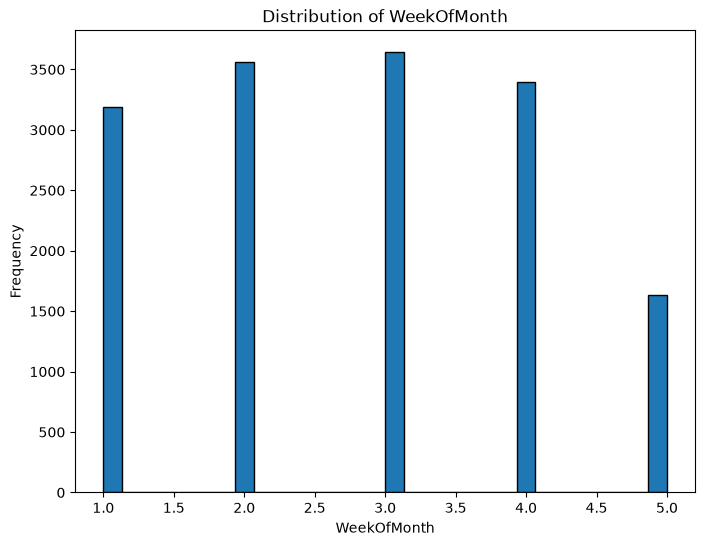

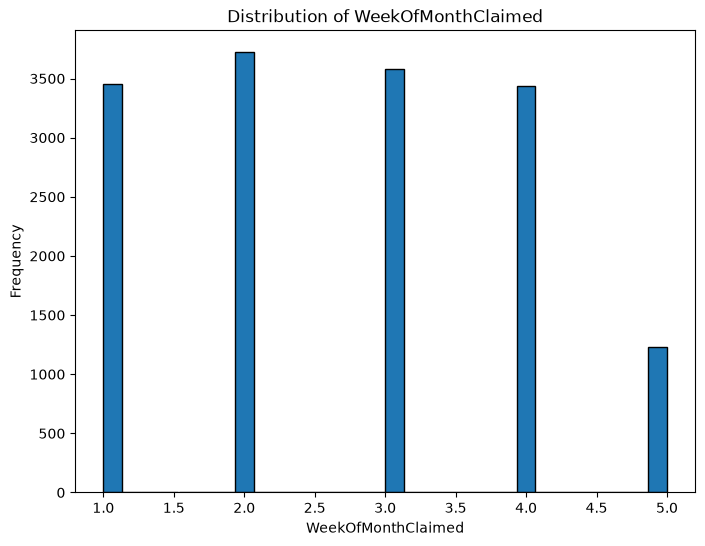

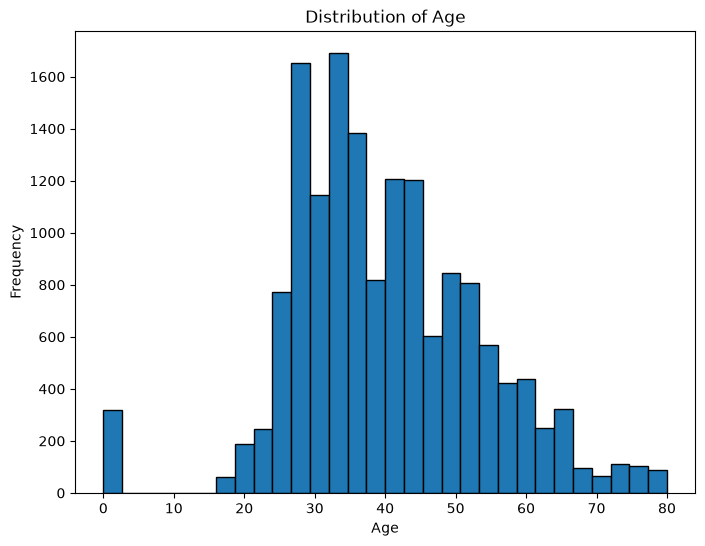

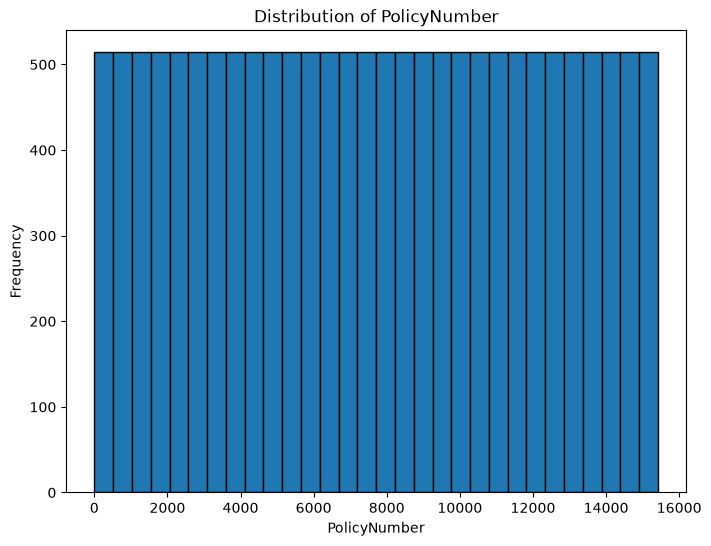

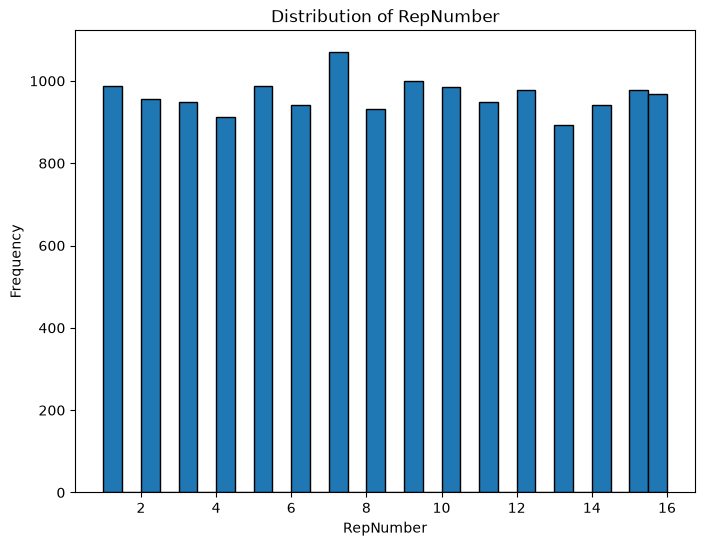

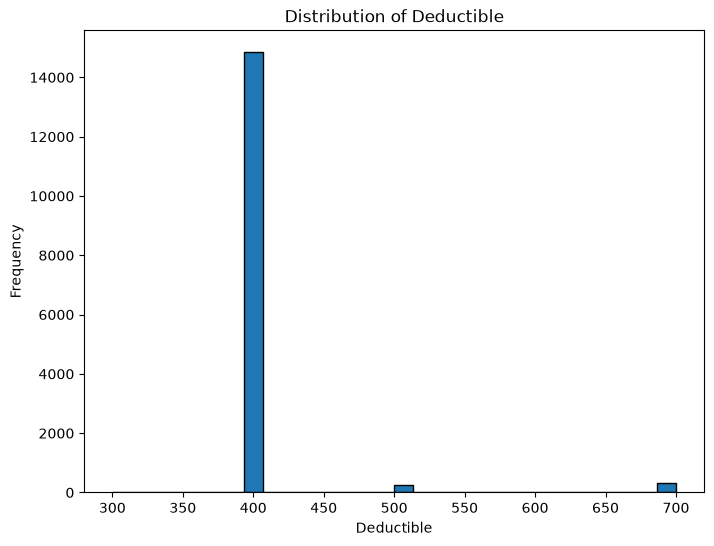

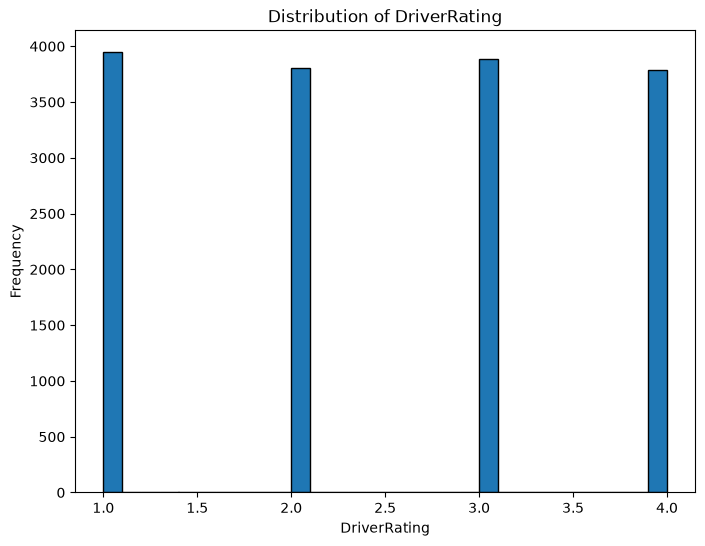

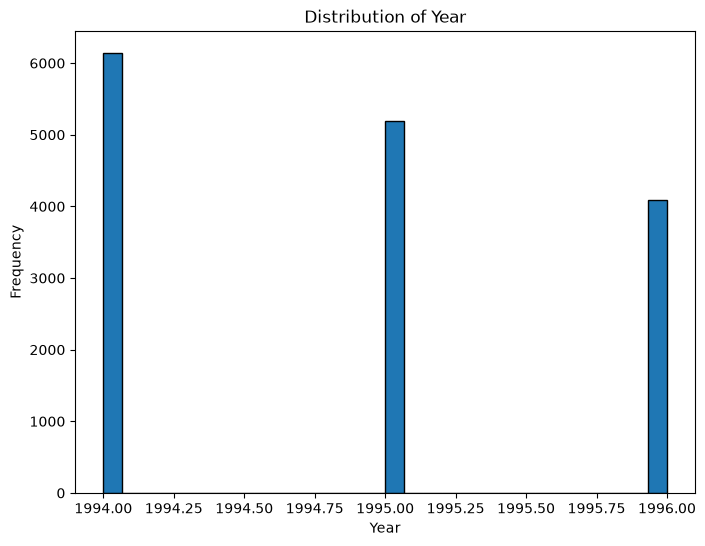

In [4]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include= ['object', 'category', 'bool']).columns.tolist()

# remove target --> we already know it is not numerical
numerical_cols.remove(TARGET)

print(df[numerical_cols].describe().T)

# plot numeric
for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.title(f'Distribution of {col}')
    plt.show()



Month - Top Categories:
Month
Jan    1411
May    1367
Mar    1360
Jun    1321
Oct    1305
Dec    1285
Apr    1280
Feb    1266
Jul    1257
Sep    1240
Nov    1201
Aug    1127
Name: count, dtype: int64


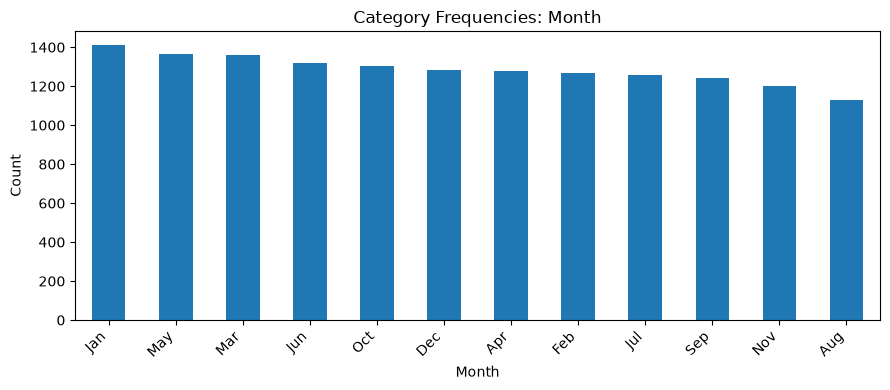


DayOfWeek - Top Categories:
DayOfWeek
Monday       2616
Friday       2445
Tuesday      2300
Thursday     2173
Wednesday    2159
Saturday     1982
Sunday       1745
Name: count, dtype: int64


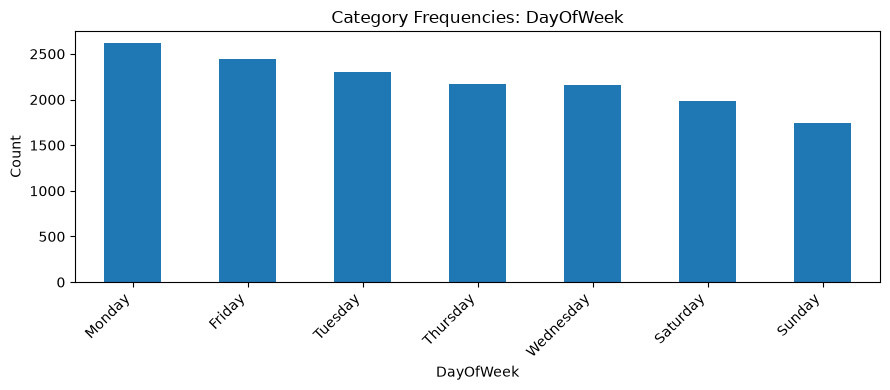


Make - Top Categories:
Make
Pontiac      3837
Toyota       3121
Honda        2801
Mazda        2354
Chevrolet    1681
Accura        472
Ford          450
VW            283
Dodge         109
Saab          108
Mercury        83
Saturn         58
Nisson         30
BMW            15
Jaguar          6
Name: count, dtype: int64


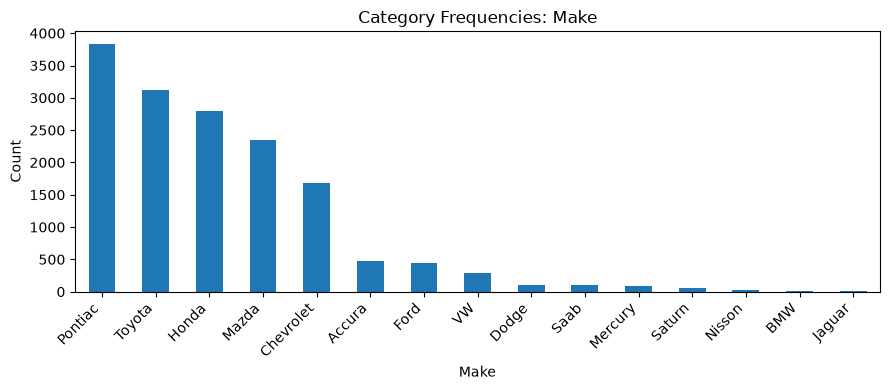


AccidentArea - Top Categories:
AccidentArea
Urban    13822
Rural     1598
Name: count, dtype: int64


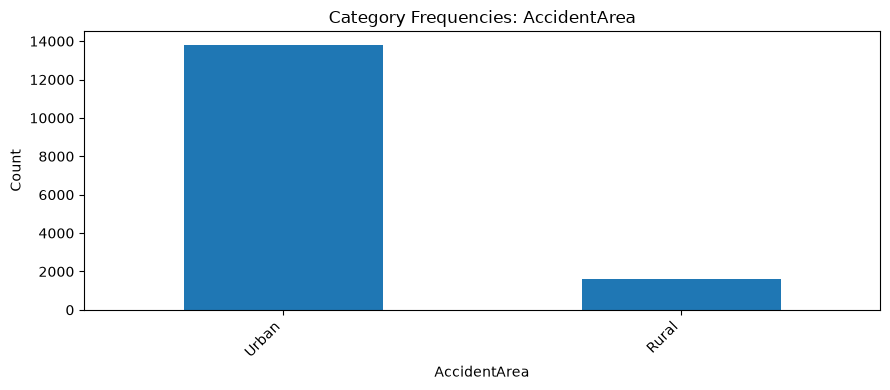


DayOfWeekClaimed - Top Categories:
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               1
Name: count, dtype: int64


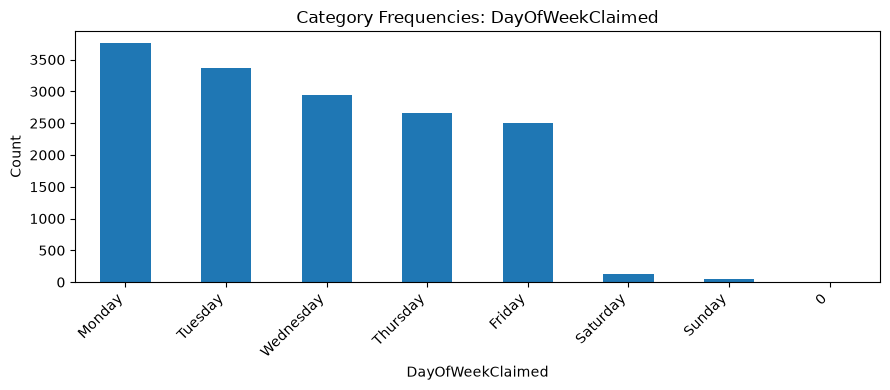


MonthClaimed - Top Categories:
MonthClaimed
Jan    1446
May    1411
Mar    1348
Oct    1339
Jun    1293
Feb    1287
Nov    1285
Apr    1271
Sep    1242
Jul    1225
Dec    1146
Aug    1126
0         1
Name: count, dtype: int64


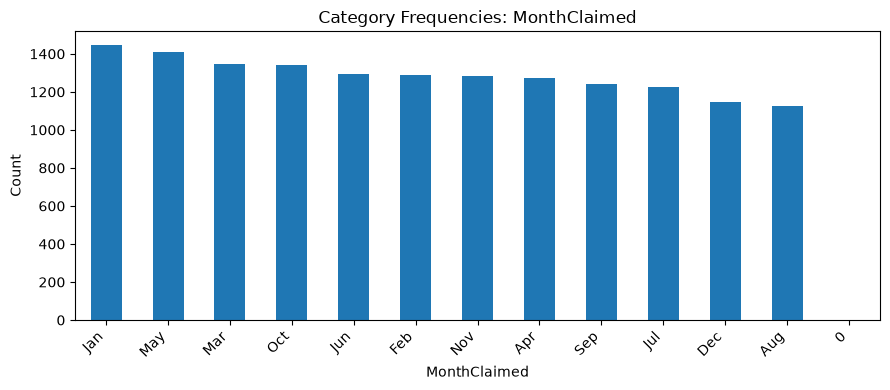


Sex - Top Categories:
Sex
Male      13000
Female     2420
Name: count, dtype: int64


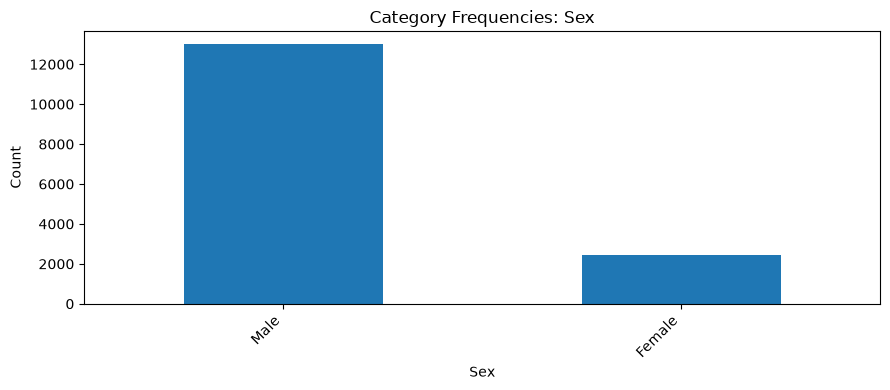


MaritalStatus - Top Categories:
MaritalStatus
Married     10625
Single       4684
Divorced       76
Widow          35
Name: count, dtype: int64


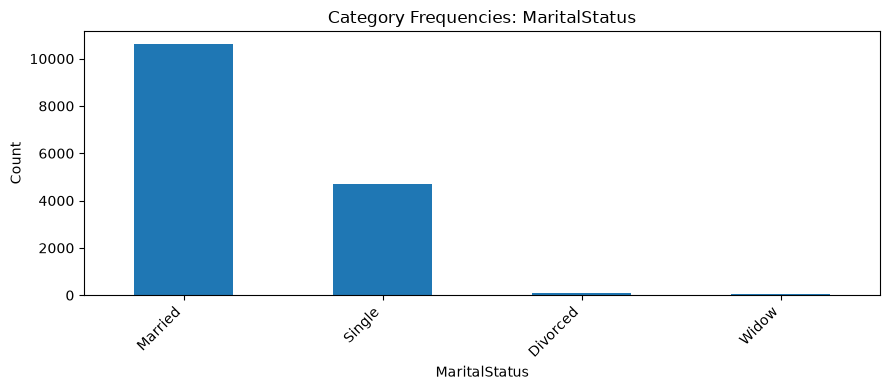


Fault - Top Categories:
Fault
Policy Holder    11230
Third Party       4190
Name: count, dtype: int64


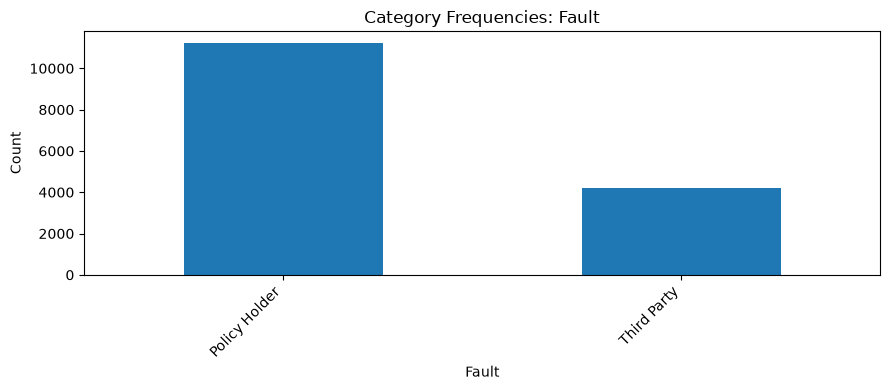


PolicyType - Top Categories:
PolicyType
Sedan - Collision       5584
Sedan - Liability       4987
Sedan - All Perils      4087
Sport - Collision        348
Utility - All Perils     340
Utility - Collision       30
Sport - All Perils        22
Utility - Liability       21
Sport - Liability          1
Name: count, dtype: int64


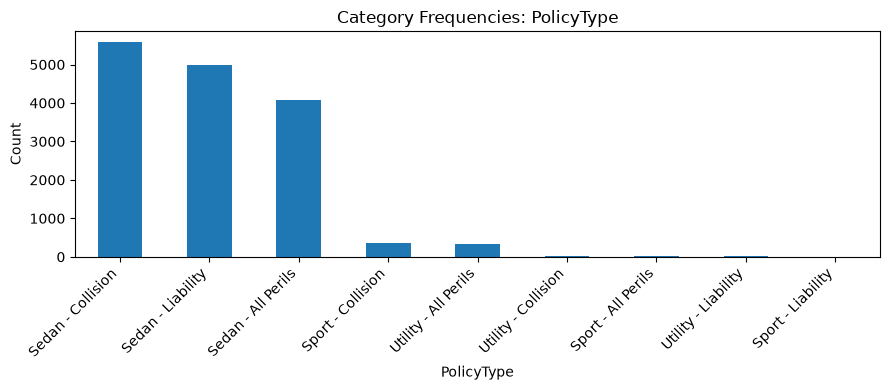


VehicleCategory - Top Categories:
VehicleCategory
Sedan      9671
Sport      5358
Utility     391
Name: count, dtype: int64


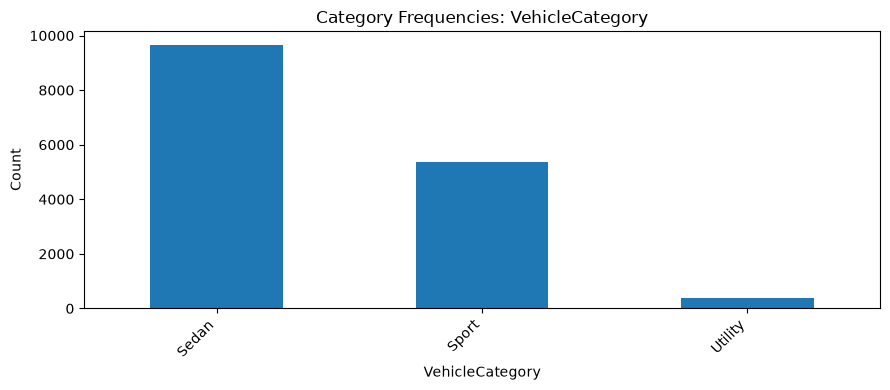


VehiclePrice - Top Categories:
VehiclePrice
20000 to 29000     8079
30000 to 39000     3533
more than 69000    2164
less than 20000    1096
40000 to 59000      461
60000 to 69000       87
Name: count, dtype: int64


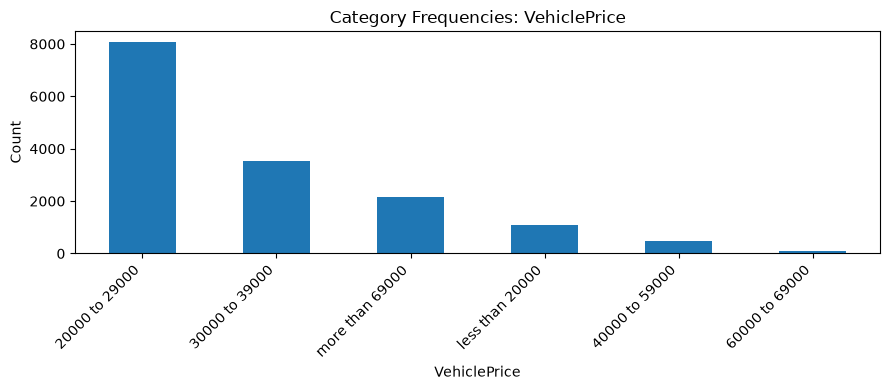


Days_Policy_Accident - Top Categories:
Days_Policy_Accident
more than 30    15247
none               55
8 to 15            55
15 to 30           49
1 to 7             14
Name: count, dtype: int64


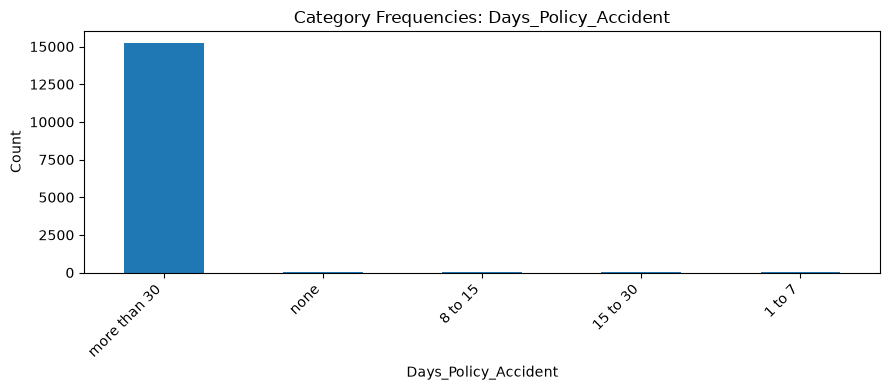


Days_Policy_Claim - Top Categories:
Days_Policy_Claim
more than 30    15342
15 to 30           56
8 to 15            21
none                1
Name: count, dtype: int64


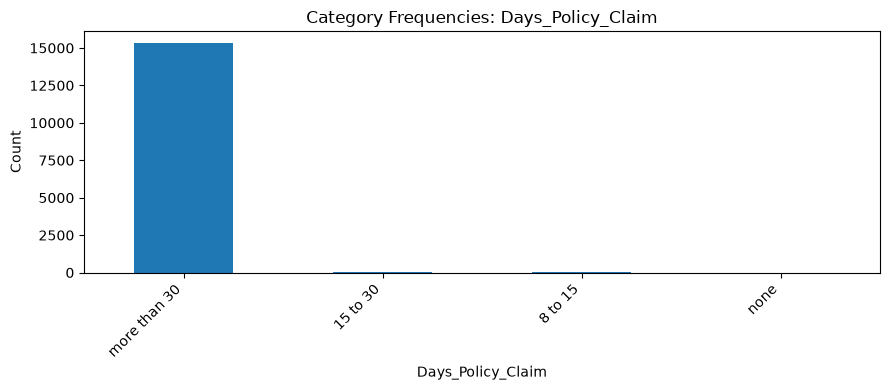


PastNumberOfClaims - Top Categories:
PastNumberOfClaims
2 to 4         5485
none           4352
1              3573
more than 4    2010
Name: count, dtype: int64


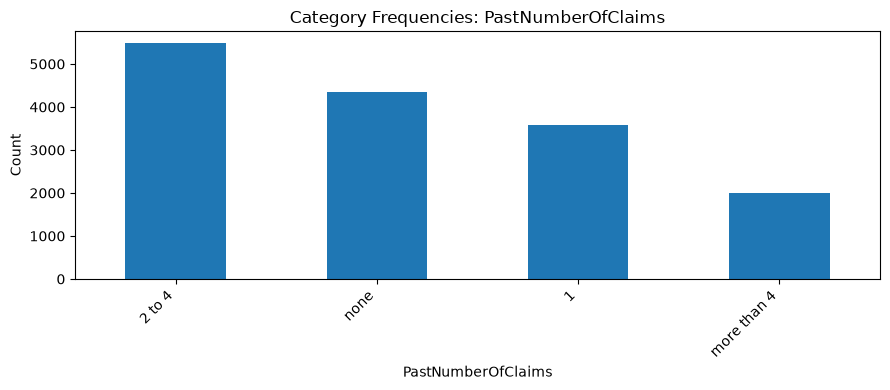


AgeOfVehicle - Top Categories:
AgeOfVehicle
7 years        5807
more than 7    3981
6 years        3448
5 years        1357
new             373
4 years         229
3 years         152
2 years          73
Name: count, dtype: int64


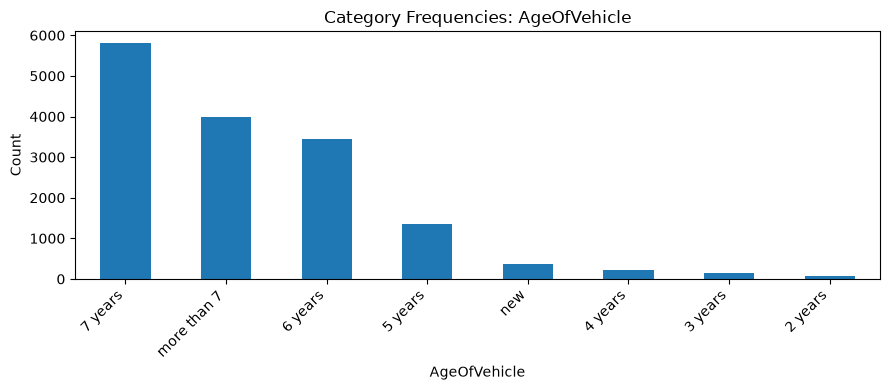


AgeOfPolicyHolder - Top Categories:
AgeOfPolicyHolder
31 to 35    5593
36 to 40    4043
41 to 50    2828
51 to 65    1392
26 to 30     613
over 65      508
16 to 17     320
21 to 25     108
18 to 20      15
Name: count, dtype: int64


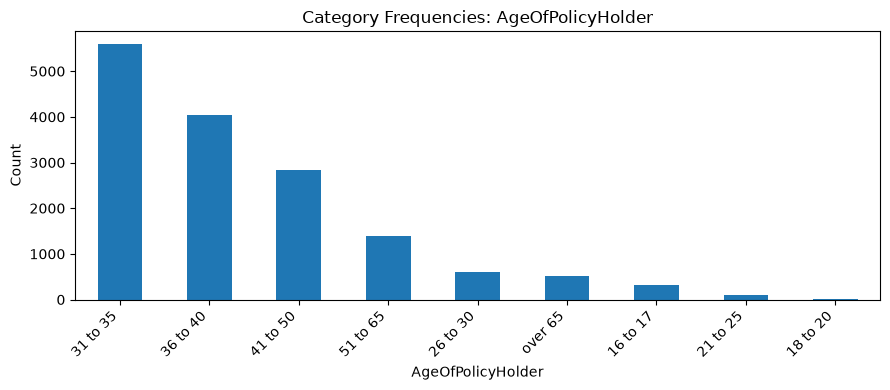


PoliceReportFiled - Top Categories:
PoliceReportFiled
No     14992
Yes      428
Name: count, dtype: int64


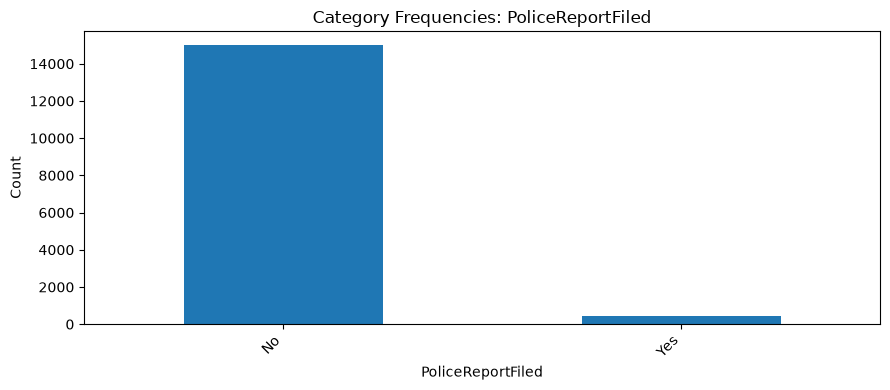


WitnessPresent - Top Categories:
WitnessPresent
No     15333
Yes       87
Name: count, dtype: int64


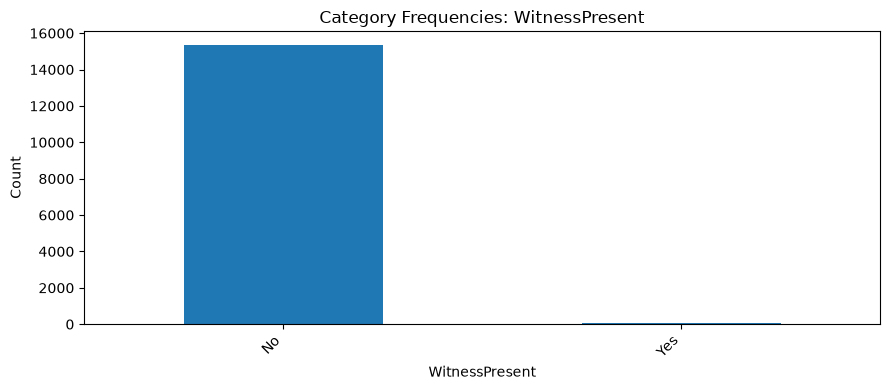


AgentType - Top Categories:
AgentType
External    15179
Internal      241
Name: count, dtype: int64


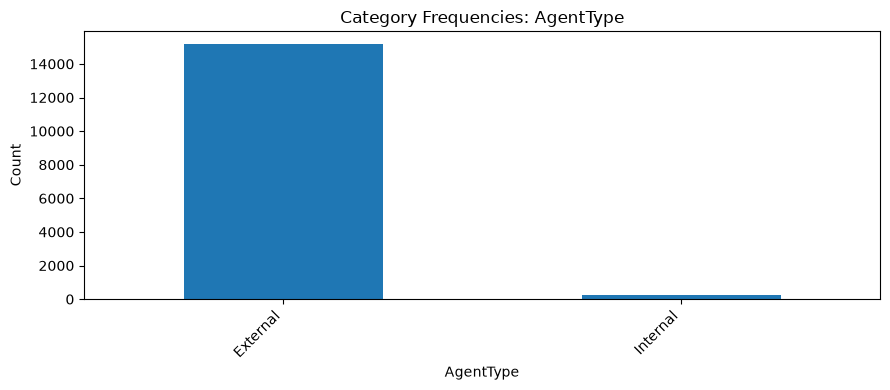


NumberOfSuppliments - Top Categories:
NumberOfSuppliments
none           7047
more than 5    3867
1 to 2         2489
3 to 5         2017
Name: count, dtype: int64


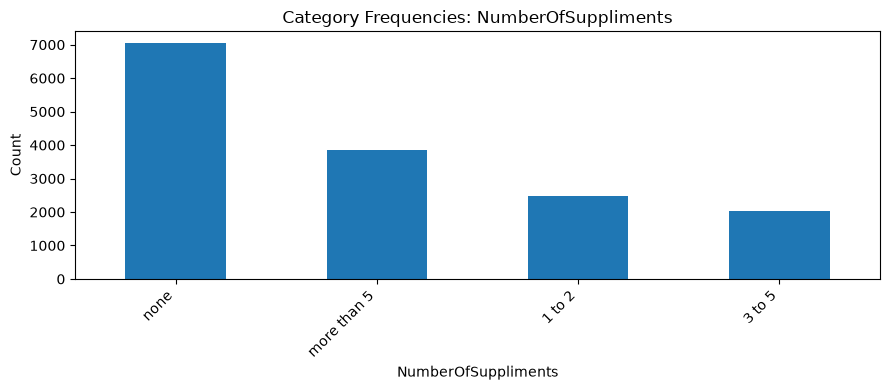


AddressChange_Claim - Top Categories:
AddressChange_Claim
no change         14324
4 to 8 years        631
2 to 3 years        291
1 year              170
under 6 months        4
Name: count, dtype: int64


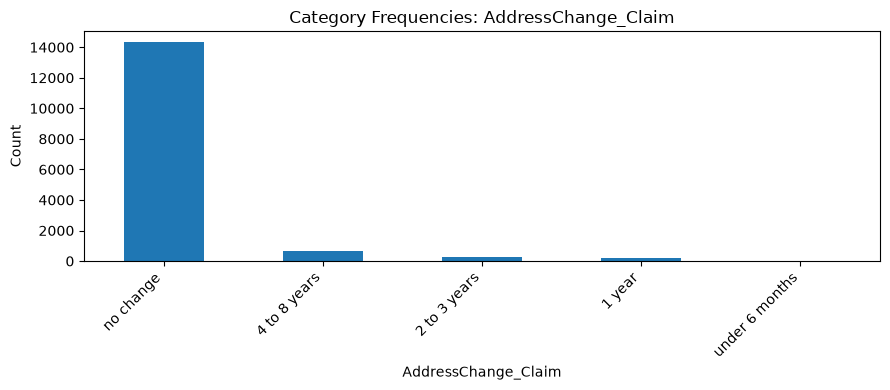


NumberOfCars - Top Categories:
NumberOfCars
1 vehicle      14316
2 vehicles       709
3 to 4           372
5 to 8            21
more than 8        2
Name: count, dtype: int64


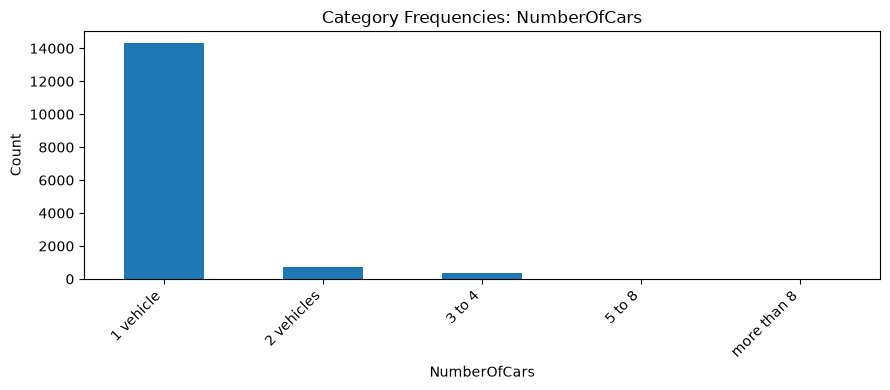


BasePolicy - Top Categories:
BasePolicy
Collision     5962
Liability     5009
All Perils    4449
Name: count, dtype: int64


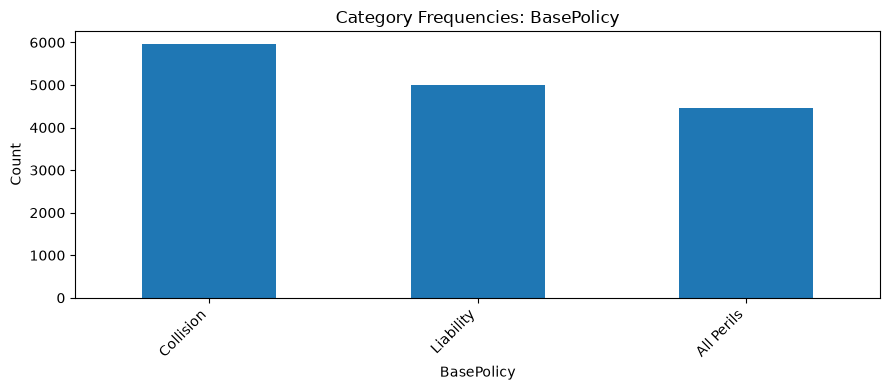

In [5]:
# categorical
for col in categorical_cols:
    print(f"\n{col} - Top Categories:")
    print(df[col].value_counts(dropna=False).head(15))
    df[col].value_counts(dropna=False).head(15).plot(kind='bar', figsize = (9,4))
    # head(15) gives the top 15 categories and figsize = (9,4) sets the size of the plot 9 is the width and 4 is the height

    plt.title(f"Category Frequencies: {col}")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    

In [6]:
#outlier results

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_results.append((col, len(outliers)))

print(outlier_results)
# len(outliers) --> means the number of outliers in each column




[('WeekOfMonth', 0), ('WeekOfMonthClaimed', 0), ('Age', 547), ('PolicyNumber', 0), ('RepNumber', 0), ('Deductible', 582), ('DriverRating', 0), ('Year', 0)]


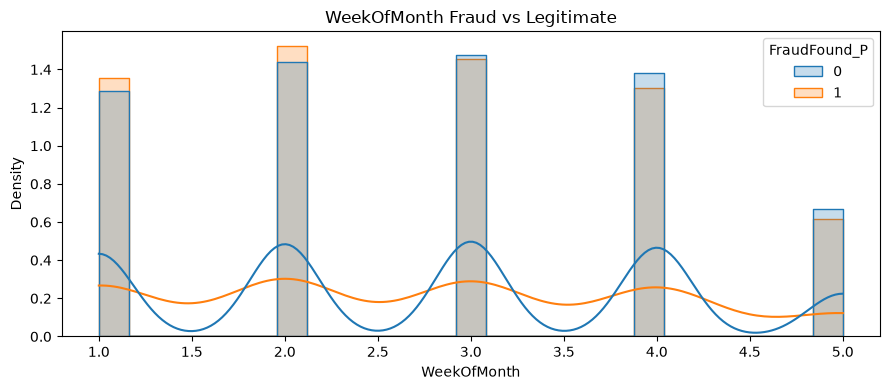

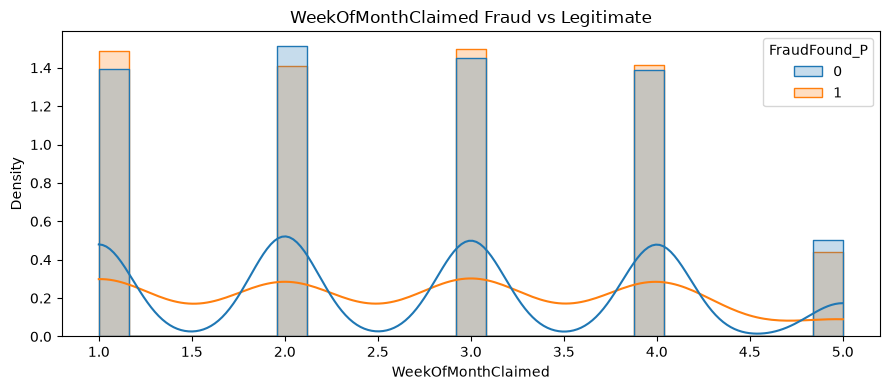

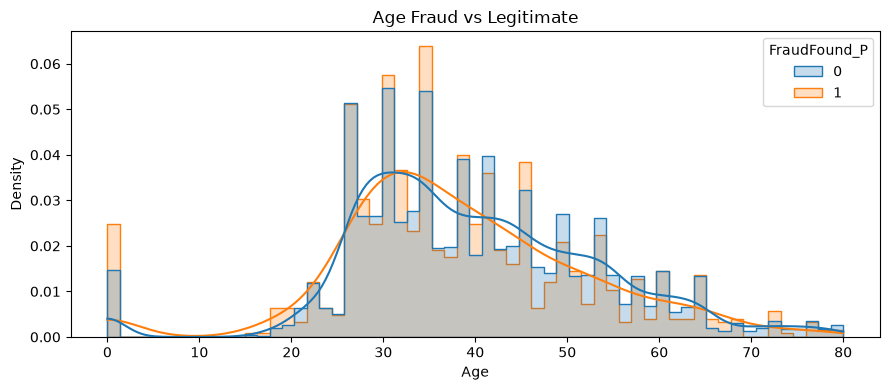

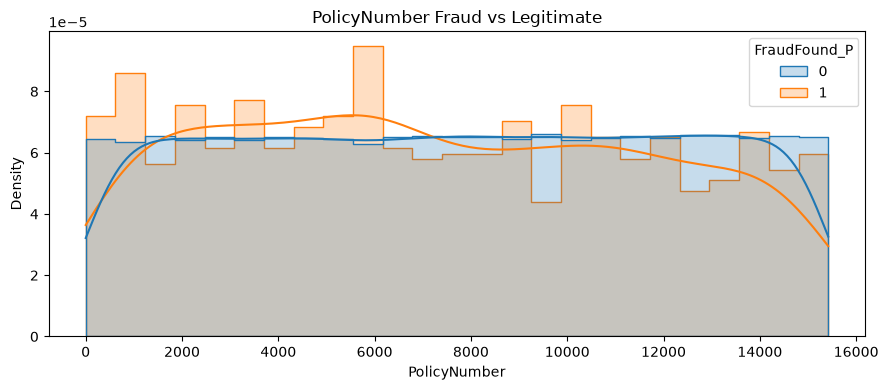

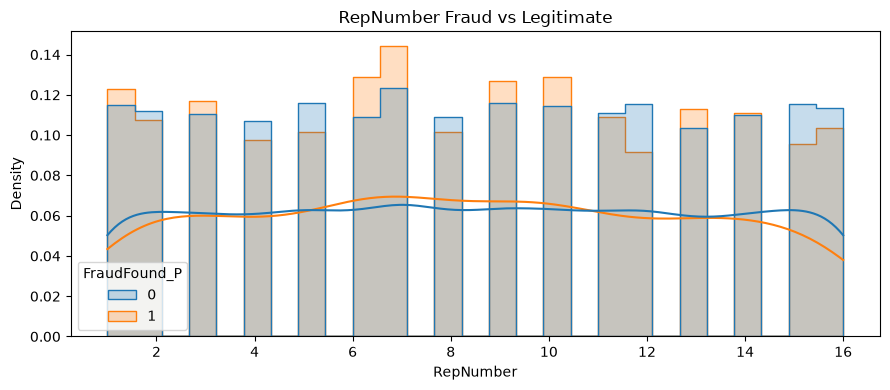

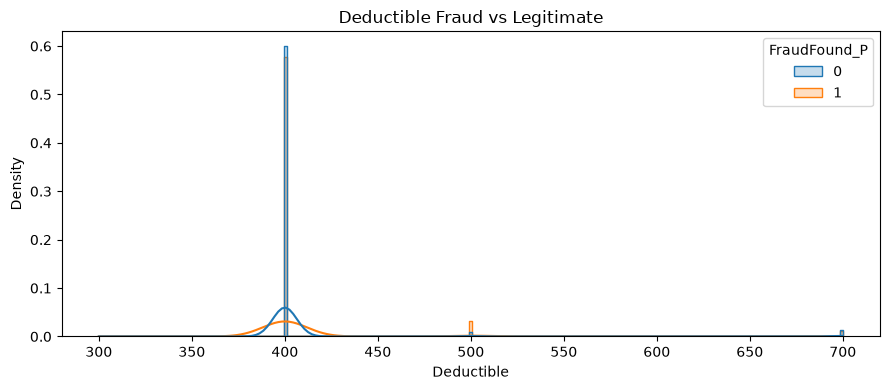

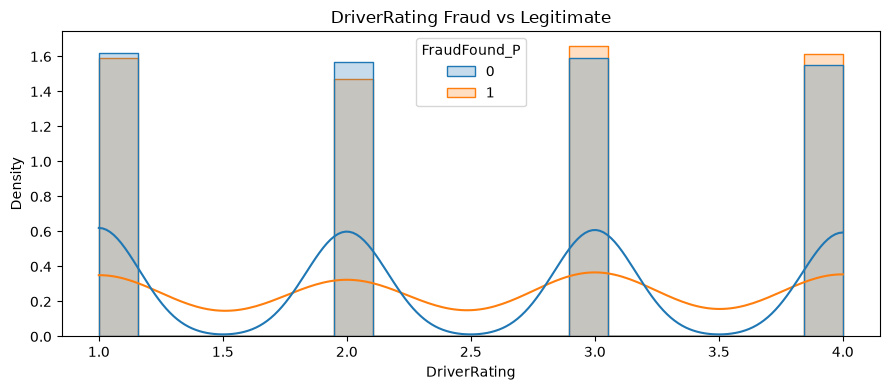

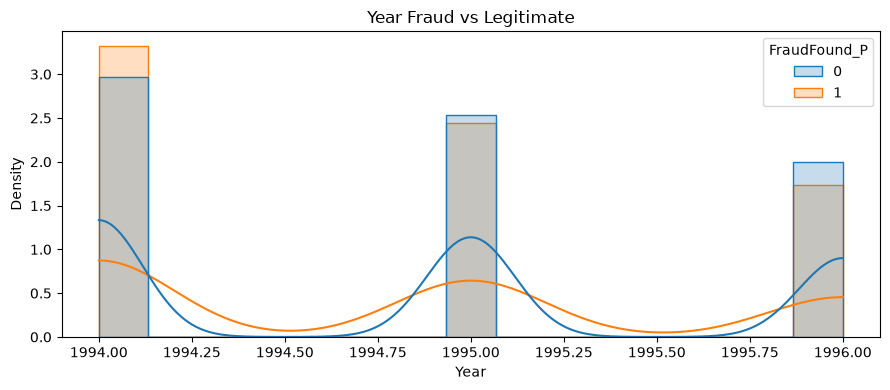

In [7]:
# feature distribution between fraudulent and legitimate transactions

target = TARGET

for col in numerical_cols:
    plt.figure(figsize = (9,4))

    sns.histplot(data=df, x=col, hue=target, stat="density", common_norm=False, element="step", kde=True)
    # explain each parameter
    # hue=target: Colors the histogram based on the target variable
    # stat="density": Normalizes the histogram to represent a probability density
    # common_norm=False: Does not normalize the histograms to have the same total area
    # element="step": Plots the histogram as a step function
    # kde=True: Plots a kernel density estimate
    plt.title(f"{col} Fraud vs Legitimate")
    plt.tight_layout() # -> tight_layout does what: Adjusts the layout to prevent overlapping
    plt.show()
    

In [8]:
# categorical 

for col in categorical_cols:
    fraud_rates = df.groupby(col, observed=True)[target].agg(
        Fraud_Rate= "mean",
        Claim_Count= "size"
    )
    # Calculates the fraud rate and claim count for each category in the specified column

    fraud_rates = fraud_rates.sort_values("Fraud_Rate", ascending=False)
    print(fraud_rates.head(15))

       Fraud_Rate  Claim_Count
Month                         
Mar      0.075000         1360
Aug      0.074534         1127
May      0.068764         1367
Feb      0.064771         1266
Apr      0.062500         1280
Jan      0.061658         1411
Sep      0.061290         1240
Jun      0.060560         1321
Oct      0.053640         1305
Dec      0.048249         1285
Jul      0.047733         1257
Nov      0.038301         1201
           Fraud_Rate  Claim_Count
DayOfWeek                         
Sunday       0.069914         1745
Saturday     0.066599         1982
Friday       0.062986         2445
Monday       0.061162         2616
Thursday     0.055223         2173
Wednesday    0.053265         2159
Tuesday      0.052174         2300
           Fraud_Rate  Claim_Count
Make                              
Mecedes      0.250000            4
Accura       0.125000          472
Saturn       0.103448           58
Saab         0.101852          108
Ford         0.073333          450
Mercur

before we clean, lets do a quick feature audit --> features that might have been taken after the prediction

## Goal: which is better? Gradient boosting or random forest? SMOTE or class weighting? And do we beat the baselines?
Think of it like a school year:
* **1994 = study book** (the model learns from it)
* **1995 = practice test** (we grade every model here)
* **1996 = final exam** (locked! we don't touch it today)

**How we grade (5 numbers):**
* **PR-AUC:** how well the model puts fraud near the top of its list (1.0 = perfect, ≈ 0.058 = random guessing)
* **Recall @ top 10% / top 20%:** if investigators check the riskiest 10% (or 20%) of claims, what share of ALL fraud do they catch?
* **Fraud recall:** using the model's normal yes/no answer (score ≥ 0.5 = "fraud"), what share of fraud did it catch?
* **Precision:** of the claims the model called fraud, how many really were fraud?
* **% flagged:** how many claims the model called fraud (not a score, it explains recall vs precision)
* **F1:** one number mixing "how many flags were right" (precision) and fraud recall. Only high if both are high.

In [9]:
# Step 1: throw away columns that are "cheating" (we might only learn them AFTER the claim is checked)
cheat_columns = ['Fault', 'PolicyNumber', 'RepNumber', 'AgeOfPolicyHolder', 'PoliceReportFiled',
                 'WitnessPresent', 'NumberOfSuppliments', 'AddressChange_Claim', 'Year']
features = [c for c in df.columns if c not in cheat_columns and c != TARGET]

# Columns with words (like "Honda") are categories. A few number columns are really categories too.
category_cols = [c for c in features if df[c].dtype == 'object' or str(df[c].dtype) == 'str']
category_cols += ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating', 'Deductible']
print(len(features), 'features we keep')
assert TARGET not in features                       # check: the answer is not an input

23 features we keep


In [10]:
# Step 2: split by year
study = df[df['Year'] == 1994].copy()     # learn from this
practice = df[df['Year'] == 1995].copy()  # grade on this
# 1996 = final exam. We don't even make a variable for it.

# Clean: Age = 0 means "we don't know the age". Fill it with the normal (median) age from the STUDY year only.
age_median = study.loc[study['Age'] > 0, 'Age'].median()
for d in [study, practice]:
    d['AgeMissing'] = (d['Age'] == 0).astype(int)   # remember that it was missing
    d['Age'] = d['Age'].replace(0, age_median)

print('study   :', len(study), 'claims,', study[TARGET].sum(), 'fraud')
print('practice:', len(practice), 'claims,', practice[TARGET].sum(), 'fraud')
assert set(study.index).isdisjoint(practice.index)  # check: no claim is in both

study   : 6142 claims, 409 fraud
practice: 5195 claims, 301 fraud


In [15]:
# Step 3: computers only read numbers, so turn each category into 0/1 columns ("one-hot")
def to_numbers(d, columns_to_match=None):
    X = pd.get_dummies(d[features + ['AgeMissing']], columns=category_cols, dtype=int)
    if columns_to_match is not None:
        X = X.reindex(columns=columns_to_match, fill_value=0)   # make the columns line up with the study year
    return X

X_study = to_numbers(study)
X_practice = to_numbers(practice, X_study.columns)
y_study, y_practice = study[TARGET], practice[TARGET]
print(X_study.shape, X_practice.shape)
assert list(X_study.columns) == list(X_practice.columns)  # check: same columns

# The grading function: gives the 5 numbers for any list of fraud scores
from sklearn.metrics import precision_recall_curve, auc

def grade(name, scores):
    y = y_practice.to_numpy()
    order = np.argsort(-scores)                          # claims sorted from riskiest to safest
    top10 = order[:int(len(scores) * 0.10)]
    top20 = order[:int(len(scores) * 0.20)]
    precision, recall, _ = precision_recall_curve(y, scores)
    yes_no = (scores >= 0.5).astype(int)                 # the model's normal yes/no answer
    return {'model': name,
            'PR-AUC': auc(recall, precision),
            'recall @ top 10%': y[top10].sum() / y.sum(),
            'recall @ top 20%': y[top20].sum() / y.sum(),
            'fraud recall': recall_score(y, yes_no, zero_division=0),
            # precision: of the claims the model said "fraud", how many really were fraud?
            'precision': precision_score(y, yes_no, zero_division=0),
            'F1': f1_score(y, yes_no, zero_division=0),
            }

(6142, 134) (5195, 134)


## Two ways to fix "fraud is rare" (only ~6% of claims)
* **Class weighting:** tell the model "each fraud claim counts about 14x more."
* **SMOTE:** make fake fraud claims by mixing two real ones, until fraud = 50%. **Only on the study year!** Never on the practice test.

In [16]:
# Step 4: SMOTE on the STUDY year only.
# SMOTENC = SMOTE that won't make nonsense like "half Honda, half Toyota". It copies whole categories.
from imblearn.over_sampling import SMOTENC

raw = study[features + ['AgeMissing']].astype({c: str for c in category_cols})
cat_positions = [i for i, c in enumerate(raw.columns) if c != 'Age']   # everything except Age is a category
raw_smote, y_smote = SMOTENC(categorical_features=cat_positions, random_state=42).fit_resample(raw, y_study)
for c in ['WeekOfMonth', 'WeekOfMonthClaimed', 'DriverRating', 'Deductible', 'AgeMissing']:
    raw_smote[c] = raw_smote[c].astype(int)
X_smote = to_numbers(raw_smote, X_study.columns)

print('before SMOTE:', y_study.value_counts().to_dict())   # 0 = normal claims, 1 = fraud claims
print('after  SMOTE:', y_smote.value_counts().to_dict())   # SMOTE added fake fraud until it's 50/50
assert len(X_practice) == len(practice)   # check: practice test was NOT changed

before SMOTE: {0: 5733, 1: 409}
after  SMOTE: {0: 5733, 1: 5733}


In [17]:
# Step 5: the big race. 2 models x 2 fixes x 4 settings. Every combo gets the SAME settings (fair!).
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def make(model, fix, setting):
    if model == 'Random forest':
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=setting, n_jobs=-1, random_state=42,
                                      class_weight='balanced_subsample' if fix == 'class weight' else None)
    return HistGradientBoostingClassifier(max_depth=3, min_samples_leaf=setting, learning_rate=0.1, max_iter=300,
                                          early_stopping=False, random_state=42,
                                          class_weight='balanced' if fix == 'class weight' else None)

rows = []
for model in ['Random forest', 'Gradient boosting']:
    for fix in ['class weight', 'SMOTE']:
        X_train, y_train = (X_smote, y_smote) if fix == 'SMOTE' else (X_study, y_study)
        for setting in [10, 20, 50, 100]:          # min_samples_leaf: bigger = simpler model
            m = make(model, fix, setting).fit(X_train, y_train)
            scores = m.predict_proba(X_practice)[:, 1]          # fraud score for each practice claim
            rows.append({**grade(f'{model} + {fix}', scores), 'fix': fix, 'min_samples_leaf': setting})

race = pd.DataFrame(rows)
# Keep the best setting for each model + fix (best = highest PR-AUC)
best = race.sort_values('PR-AUC', ascending=False).groupby('model').first().sort_values('PR-AUC', ascending=False)
display(best.drop(columns='fix').round(3))

,PR-AUC,recall @ top 10%,recall @ top 20%,fraud recall,precision,F1,min_samples_leaf
model,,,,,,,
Gradient boosting + class weight,0.082,0.153,0.279,0.329,0.079,0.127,100
Random forest + class weight,0.078,0.130,0.259,0.528,0.081,0.141,100
Random forest + SMOTE,0.074,0.096,0.252,0.355,0.074,0.122,100
Gradient boosting + SMOTE,0.072,0.123,0.239,0.196,0.074,0.107,10


,PR-AUC,recall @ top 10%,recall @ top 20%,fraud recall,precision,F1
model,,,,,,
Random guessing,0.064,0.096,0.213,0.512,0.060,0.108
Baseline: logistic regression (no class weight),0.077,0.136,0.266,0.000,0.000,0.000
Baseline: logistic regression + class weight,0.079,0.163,0.279,0.392,0.078,0.130
WINNER: Gradient boosting + class weight,0.082,0.153,0.279,0.329,0.079,0.127


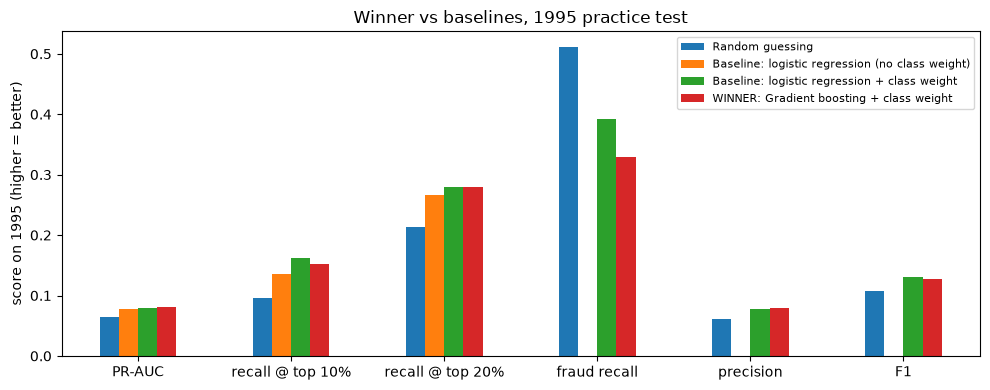

In [18]:
# Step 6: does our winner beat simple baselines? Same 1994 study year, same 1995 practice test.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Logistic regression needs numbers on similar scales, so shrink Age to a small range (learned from 1994 only)
scaler = StandardScaler().fit(X_study[['Age']])
X_study_lr, X_practice_lr = X_study.copy(), X_practice.copy()
X_study_lr[['Age']] = scaler.transform(X_study[['Age']])
X_practice_lr[['Age']] = scaler.transform(X_practice[['Age']])

lr_plain = LogisticRegression(max_iter=2000, random_state=42).fit(X_study_lr, y_study)
lr_weighted = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42).fit(X_study_lr, y_study)

# Re-train the race winner with its best setting
winner_name = best.index[0]
winner_row = best.iloc[0]
winner_model, winner_fix = winner_name.split(' + ')
X_train, y_train = (X_smote, y_smote) if winner_fix == 'SMOTE' else (X_study, y_study)
winner = make(winner_model, winner_fix, int(winner_row['min_samples_leaf'])).fit(X_train, y_train)

final = pd.DataFrame([
    grade('Random guessing', np.random.default_rng(42).random(len(y_practice))),
    grade('Baseline: logistic regression (no class weight)', lr_plain.predict_proba(X_practice_lr)[:, 1]),
    grade('Baseline: logistic regression + class weight', lr_weighted.predict_proba(X_practice_lr)[:, 1]),
    grade(f'WINNER: {winner_name}', winner.predict_proba(X_practice)[:, 1]),
]).set_index('model')
display(final.round(3))

# Picture: all 5 numbers side by side
final.T.plot(kind='bar', figsize=(10, 4), rot=0)
plt.ylabel('score on 1995 (higher = better)')
plt.title('Winner vs baselines, 1995 practice test')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## What we found (fill in after running)
* Class weighting vs SMOTE: **___** wins
* Gradient boosting vs random forest: **___** wins
* Winner vs baselines: **___**
* 1996 final exam: not touched yet ✅